# Mini Diffusion Model: DDPM → DDIM on MNIST

This notebook builds a small diffusion model from scratch and covers all four parts of the assignment:

| Part | Content |
|---|---|
| (a) | Forward diffusion $x_t = \sqrt{\bar\alpha_t}\,x_0 + \sqrt{1-\bar\alpha_t}\,\epsilon$, visualized at $t = 0, 10, 30, 60, 100$ |
| (b) | Training a time-conditioned CNN $\epsilon_\theta(x_t, t)$ with $L = \mathrm{MSE}(\epsilon, \epsilon_\theta(x_t,t))$, plus the loss curve |
| (c) | DDPM ancestral (reverse) sampling from Gaussian noise |
| (d) | DDIM sampling, and a comparison of DDPM (100 steps) with DDIM (50 and 20 steps) |

**Configuration:** $T = 100$, $\beta_t$ linear from $10^{-4}$ to $0.02$, batch size 128, 50 epochs.

**Timestep convention:** timesteps run $t = 1, \dots, T$. Every schedule tensor has length $T+1$, and index 0 holds the clean image ($\beta_0 = 0$, $\bar\alpha_0 = 1$). This makes $t = 0$ the original image, and lets DDIM step all the way to $\bar\alpha_0 = 1$ at the end.

In [1]:
import math, time, copy
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torchvision import datasets
from torchvision.utils import make_grid

SEED = 1605                                   # SID4; every random choice below is derived from it
torch.manual_seed(SEED); np.random.seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available()
                      else "mps" if torch.backends.mps.is_available() else "cpu")
print("device:", device)

FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)

# ---- configuration (from the assignment) ----
T = 100
BETA_START, BETA_END = 1e-4, 0.02
BATCH_SIZE = 128
EPOCHS = 50
LR = 1e-3

device: mps


## Data

MNIST digits are scaled from $[0,1]$ to $[-1,1]$. That way a clean image and the Gaussian noise $\epsilon \sim \mathcal N(0, I)$ are on a comparable scale. The whole training set (60k × 28 × 28) is small, so it is kept on the device as one tensor, which avoids DataLoader overhead.

In [2]:
train_set = datasets.MNIST("./data", train=True, download=True)
test_set  = datasets.MNIST("./data", train=False, download=True)

def to_tensor(ds):
    x = ds.data.float().div(255.).unsqueeze(1)           # (N,1,28,28) in [0,1]
    return x * 2 - 1, ds.targets.clone()                  # -> [-1,1]

X_train, y_train = to_tensor(train_set)
X_test,  y_test  = to_tensor(test_set)
X_train = X_train.to(device)
print(X_train.shape, X_train.min().item(), X_train.max().item())

def show_grid(x, nrow=8, ax=None, title=None):
    # x in [-1,1], shape (B,1,28,28)
    g = make_grid(((x.clamp(-1, 1) + 1) / 2).cpu(), nrow=nrow, padding=2, pad_value=1.0)
    ax = ax or plt.gca()
    ax.imshow(g.permute(1, 2, 0)[..., 0], cmap="gray", vmin=0, vmax=1)
    ax.axis("off")
    if title: ax.set_title(title)

torch.Size([60000, 1, 28, 28]) -1.0 1.0


## (a) Forward diffusion

With $\alpha_t = 1 - \beta_t$ and $\bar\alpha_t = \prod_{s=1}^{t}\alpha_s$, $x_t$ can be sampled in closed form for any $t$:

$$x_t = \sqrt{\bar\alpha_t}\,x_0 + \sqrt{1-\bar\alpha_t}\,\epsilon,\qquad \epsilon\sim\mathcal N(0, I).$$

In [3]:
class Schedule:
    # Linear beta schedule; index 0 = clean image (beta_0 = 0, alpha_bar_0 = 1). All tensors have length T+1.
    def __init__(self, beta_start, beta_end, T=T):
        self.betas = torch.cat([torch.zeros(1), torch.linspace(beta_start, beta_end, T)]).to(device)
        self.alphas = 1.0 - self.betas
        self.alpha_bars = torch.cumprod(self.alphas, dim=0)

spec = Schedule(BETA_START, BETA_END)                     # the assignment's schedule
betas, alphas, alpha_bars = spec.betas, spec.alphas, spec.alpha_bars

def q_sample(x0, t, noise=None, sch=spec):
    # Forward diffusion: x_t = sqrt(abar_t) x0 + sqrt(1 - abar_t) eps. t: (B,) long in [0, T]
    if noise is None:
        noise = torch.randn_like(x0)
    ab = sch.alpha_bars[t].view(-1, 1, 1, 1)
    return ab.sqrt() * x0 + (1 - ab).sqrt() * noise, noise

print(f"alpha_bar_T = {alpha_bars[T].item():.4f}  ->  signal coeff sqrt(abar_T) = {alpha_bars[T].sqrt().item():.3f}, "
      f"noise coeff sqrt(1-abar_T) = {(1 - alpha_bars[T]).sqrt().item():.3f}")

alpha_bar_T = 0.3636  ->  signal coeff sqrt(abar_T) = 0.603, noise coeff sqrt(1-abar_T) = 0.798


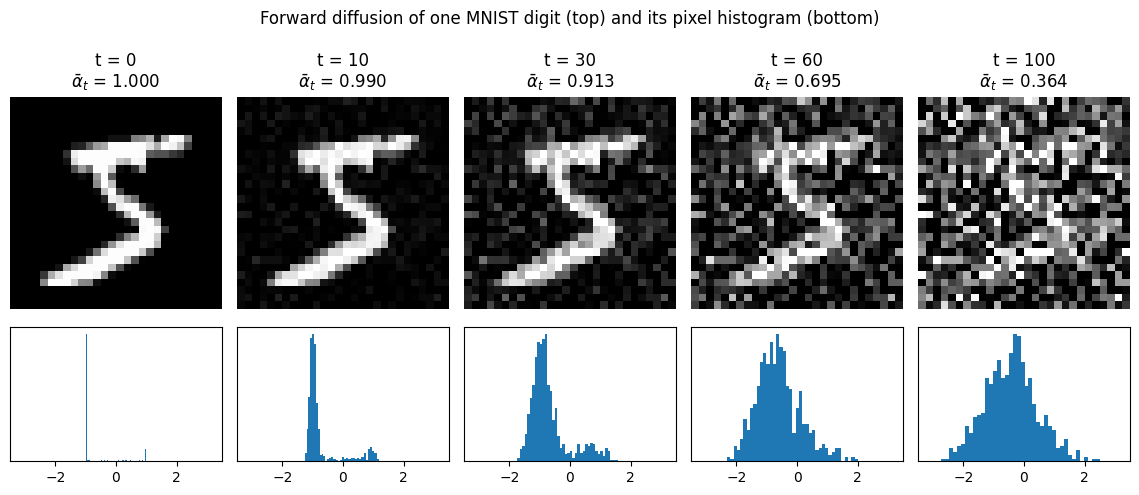

In [4]:
x0 = X_train[0:1]
show_ts = [0, 10, 30, 60, 100]
g = torch.Generator(device="cpu").manual_seed(SEED + 1)
eps = torch.randn(x0.shape, generator=g).to(device)       # same eps for every t, so only the scaling changes

fig, axes = plt.subplots(2, len(show_ts), figsize=(2.3 * len(show_ts), 5),
                         gridspec_kw={"height_ratios": [3, 1.3]})
for i, t in enumerate(show_ts):
    xt, _ = q_sample(x0, torch.tensor([t], device=device), eps)
    axes[0, i].imshow(xt[0, 0].cpu(), cmap="gray", vmin=-1, vmax=1)
    axes[0, i].set_title(f"t = {t}\n" + rf"$\bar\alpha_t$ = {alpha_bars[t].item():.3f}")
    axes[0, i].axis("off")
    axes[1, i].hist(xt.flatten().cpu().numpy(), bins=40, color="tab:blue")
    axes[1, i].set_yticks([]); axes[1, i].set_xlim(-3.5, 3.5)
fig.suptitle("Forward diffusion of one MNIST digit (top) and its pixel histogram (bottom)")
plt.tight_layout(); plt.savefig(FIG_DIR / "a_forward_diffusion.png", dpi=150); plt.show()

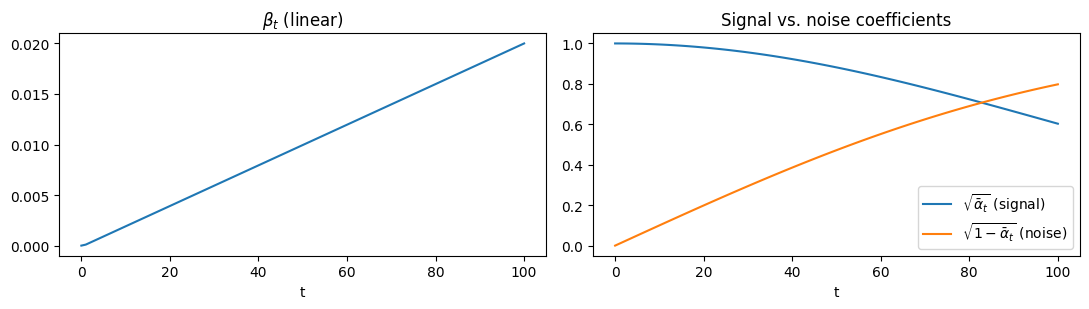

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ts = np.arange(T + 1)
ax[0].plot(ts, betas.cpu()); ax[0].set_title(r"$\beta_t$ (linear)"); ax[0].set_xlabel("t")
ax[1].plot(ts, alpha_bars.sqrt().cpu(), label=r"$\sqrt{\bar\alpha_t}$ (signal)")
ax[1].plot(ts, (1 - alpha_bars).sqrt().cpu(), label=r"$\sqrt{1-\bar\alpha_t}$ (noise)")
ax[1].set_xlabel("t"); ax[1].legend(); ax[1].set_title("Signal vs. noise coefficients")
plt.tight_layout(); plt.savefig(FIG_DIR / "a_schedule.png", dpi=150); plt.show()

**Observation.** As $t$ grows the digit fades and the pixel histogram moves from MNIST's two spikes (background at −1, strokes at +1) toward a Gaussian. With the configuration we were given ($T=100$, $\beta_T = 0.02$), though, $\bar\alpha_{100} \approx 0.37$. So $x_{100}$ still has a signal coefficient of about 0.6, and the digit is still faintly visible at $t=100$. The original DDPM setup uses $T=1000$ and ends at $\bar\alpha_T \approx 4\times10^{-5}$, which is essentially pure noise. We return to this mismatch in the discussion, because sampling starts from $x_T \sim \mathcal N(0,I)$.

## (b) Noise-prediction network

The network $\epsilon_\theta(x_t, t)$ is a small U-Net-style CNN that meets the assignment's requirements:

* **≥ 4 conv layers:** it has 18 `Conv2d` / `ConvTranspose2d` layers.
* **Nonlinear activations:** ReLU after every GroupNorm, and in the time MLP.
* **Timestep conditioning:** $t$ goes through a sinusoidal embedding and an MLP. Each residual block then adds a learned per-channel projection of that embedding to its feature maps.
* **Same output shape as input:** the 1 × 28 × 28 input passes through 28 → 14 → 7 → 14 → 28, and a final 1-channel conv gives a 1 × 28 × 28 output.

In [6]:
class SinusoidalEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, t):
        half = self.dim // 2
        freqs = torch.exp(-math.log(10000) * torch.arange(half, device=t.device) / half)
        args = t.float()[:, None] * freqs[None]
        return torch.cat([args.sin(), args.cos()], dim=1)


class ResBlock(nn.Module):
    # conv -> GN -> ReLU -> (+ time embedding) -> conv -> GN -> ReLU, with a residual connection
    def __init__(self, c_in, c_out, t_dim):
        super().__init__()
        self.conv1 = nn.Conv2d(c_in, c_out, 3, padding=1)
        self.norm1 = nn.GroupNorm(8, c_out)
        self.time = nn.Linear(t_dim, c_out)
        self.conv2 = nn.Conv2d(c_out, c_out, 3, padding=1)
        self.norm2 = nn.GroupNorm(8, c_out)
        self.skip = nn.Conv2d(c_in, c_out, 1) if c_in != c_out else nn.Identity()

    def forward(self, x, t_emb):
        h = F.relu(self.norm1(self.conv1(x)))
        h = h + self.time(t_emb)[:, :, None, None]          # condition on t
        h = F.relu(self.norm2(self.conv2(h)))
        return h + self.skip(x)


class MiniUNet(nn.Module):
    def __init__(self, ch=32, t_dim=128):
        super().__init__()
        self.t_embed = nn.Sequential(SinusoidalEmbedding(t_dim), nn.Linear(t_dim, t_dim),
                                     nn.ReLU(), nn.Linear(t_dim, t_dim))
        self.inc = nn.Conv2d(1, ch, 3, padding=1)                              # 28x28
        self.down1 = ResBlock(ch, ch, t_dim)
        self.pool1 = nn.Conv2d(ch, 2 * ch, 4, stride=2, padding=1)             # -> 14x14
        self.down2 = ResBlock(2 * ch, 2 * ch, t_dim)
        self.pool2 = nn.Conv2d(2 * ch, 4 * ch, 4, stride=2, padding=1)         # -> 7x7
        self.mid = ResBlock(4 * ch, 4 * ch, t_dim)
        self.up2 = nn.ConvTranspose2d(4 * ch, 2 * ch, 4, stride=2, padding=1)  # -> 14x14
        self.dec2 = ResBlock(4 * ch, 2 * ch, t_dim)
        self.up1 = nn.ConvTranspose2d(2 * ch, ch, 4, stride=2, padding=1)      # -> 28x28
        self.dec1 = ResBlock(2 * ch, ch, t_dim)
        self.outc = nn.Conv2d(ch, 1, 1)

    def forward(self, x, t):
        te = self.t_embed(t)
        h0 = self.inc(x)
        h1 = self.down1(h0, te)
        h2 = self.down2(self.pool1(h1), te)
        h = self.mid(self.pool2(h2), te)
        h = self.dec2(torch.cat([self.up2(h), h2], dim=1), te)
        h = self.dec1(torch.cat([self.up1(h), h1], dim=1), te)
        return self.outc(h)


model = MiniUNet().to(device)
n_params = sum(p.numel() for p in model.parameters())
n_convs = sum(isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)) for m in model.modules())
with torch.no_grad():
    out = model(torch.randn(4, 1, 28, 28, device=device), torch.randint(1, T + 1, (4,), device=device))
print(f"parameters: {n_params:,} | conv layers: {n_convs} | output shape: {tuple(out.shape)}")

parameters: 940,193 | conv layers: 18 | output shape: (4, 1, 28, 28)


### Training

Algorithm 1 from Ho et al. (2020): for each image, draw $t \sim \mathcal U\{1,\dots,T\}$ and $\epsilon \sim \mathcal N(0,I)$, build $x_t$ with `q_sample`, and minimize $\lVert \epsilon - \epsilon_\theta(x_t,t)\rVert^2$.

Training uses AdamW with a cosine learning-rate decay. We also keep an exponential moving average (EMA) of the weights and use the EMA weights for sampling. The EMA decay warms up toward 0.999. Diffusion implementations do this as standard because it smooths out the noisy late-training updates and gives cleaner samples.

In [7]:
def train(model, sch=spec, epochs=EPOCHS, ckpt="ddpm_mnist.pt"):
    opt = torch.optim.AdamW(model.parameters(), lr=LR)
    steps_per_epoch = math.ceil(len(X_train) / BATCH_SIZE)
    lr_sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs * steps_per_epoch)
    ema = copy.deepcopy(model).eval().requires_grad_(False)

    iter_losses, epoch_losses = [], []
    step, t0 = 0, time.time()
    for epoch in range(epochs):
        model.train()
        perm = torch.randperm(len(X_train), device=device)
        running = 0.0
        for i in range(steps_per_epoch):
            x0 = X_train[perm[i * BATCH_SIZE:(i + 1) * BATCH_SIZE]]
            t = torch.randint(1, T + 1, (x0.shape[0],), device=device)
            xt, eps = q_sample(x0, t, sch=sch)
            loss = F.mse_loss(model(xt, t), eps)                  # L = MSE(eps, eps_theta(x_t, t))

            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step(); lr_sched.step()
            step += 1
            decay = min(0.999, (1 + step) / (10 + step))          # EMA warm-up
            with torch.no_grad():
                for pe, pm in zip(ema.parameters(), model.parameters()):
                    pe.lerp_(pm, 1 - decay)

            l = loss.item()
            iter_losses.append(l); running += l
        epoch_losses.append(running / steps_per_epoch)
        if epoch % 5 == 0 or epoch == epochs - 1:
            print(f"epoch {epoch + 1:3d}/{epochs}  loss {epoch_losses[-1]:.4f}  ({time.time() - t0:.0f}s)")

    torch.save({"model": model.state_dict(), "ema": ema.state_dict()}, ckpt)
    return ema, iter_losses, epoch_losses


ema, iter_losses, epoch_losses = train(model)

epoch   1/50  loss 0.1260  (101s)


epoch   6/50  loss 0.0605  (609s)


epoch  11/50  loss 0.0574  (1110s)


epoch  16/50  loss 0.0559  (1639s)


epoch  21/50  loss 0.0548  (2184s)


...

epoch  31/50  loss 0.0535  (3200s)


epoch  36/50  loss 0.0527  (3710s)


epoch  41/50  loss 0.0523  (4215s)


epoch  46/50  loss 0.0521  (4724s)


epoch  50/50  loss 0.0521  (5127s)


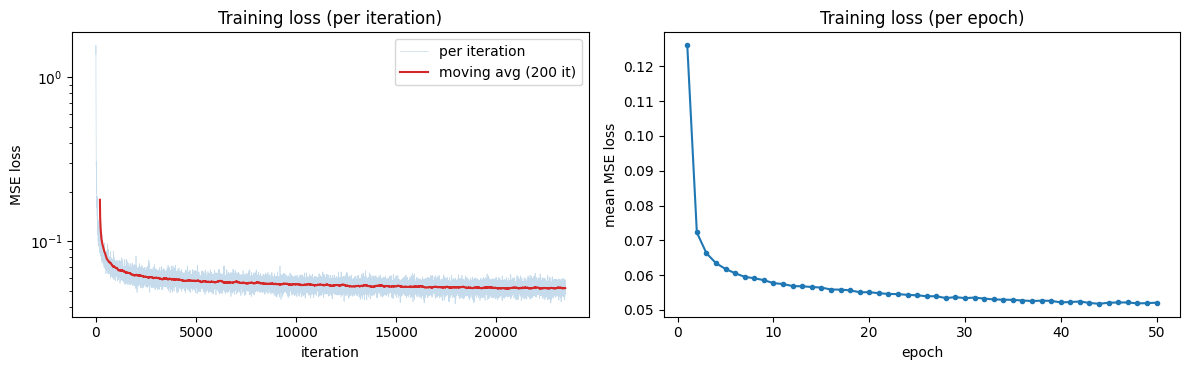

first epoch 0.1260 -> last epoch 0.0521


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
it = np.arange(len(iter_losses))
k = 200
smooth = np.convolve(iter_losses, np.ones(k) / k, mode="valid")
ax[0].plot(it, iter_losses, alpha=0.25, lw=0.5, label="per iteration")
ax[0].plot(it[k - 1:], smooth, color="tab:red", label=f"moving avg ({k} it)")
ax[0].set_yscale("log"); ax[0].set_xlabel("iteration"); ax[0].set_ylabel("MSE loss")
ax[0].set_title("Training loss (per iteration)"); ax[0].legend()
ax[1].plot(np.arange(1, EPOCHS + 1), epoch_losses, marker="o", ms=3)
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("mean MSE loss"); ax[1].set_title("Training loss (per epoch)")
plt.tight_layout(); plt.savefig(FIG_DIR / "b_training_loss.png", dpi=150); plt.show()
print(f"first epoch {epoch_losses[0]:.4f} -> last epoch {epoch_losses[-1]:.4f}")

The loss falls quickly over the first epoch and then flattens out slowly. It cannot reach zero: at small $t$ the image dominates $x_t$, so the noise in it is close to unpredictable, and those timesteps keep the average MSE above zero. The next cell splits the held-out loss by timestep to show this.

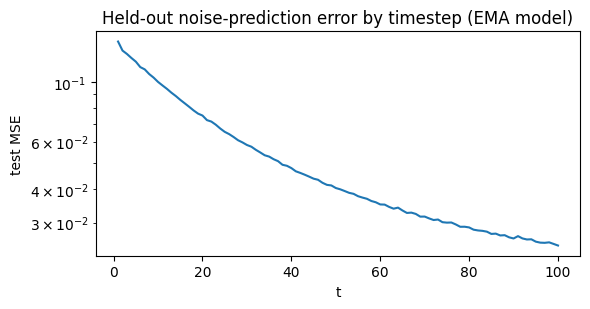

test MSE averaged over t: 0.0516


In [9]:
@torch.no_grad()
def loss_per_t(net, X, n=2000, sch=spec):
    X = X[:n].to(device)
    out = []
    for t_val in range(1, T + 1):
        t = torch.full((len(X),), t_val, device=device, dtype=torch.long)
        xt, eps = q_sample(X, t, sch=sch)
        out.append(F.mse_loss(net(xt, t), eps).item())
    return np.array(out)

test_lpt = loss_per_t(ema, X_test)
plt.figure(figsize=(6, 3.2))
plt.plot(np.arange(1, T + 1), test_lpt)
plt.xlabel("t"); plt.ylabel("test MSE"); plt.yscale("log"); plt.title("Held-out noise-prediction error by timestep (EMA model)")
plt.tight_layout(); plt.savefig(FIG_DIR / "b_loss_per_t.png", dpi=150); plt.show()
print(f"test MSE averaged over t: {test_lpt.mean():.4f}")

## (c) DDPM sampling

Algorithm 2 from Ho et al. Start from $x_T \sim \mathcal N(0, I)$, then for $t = T, \dots, 1$:

$$x_{t-1} = \frac{1}{\sqrt{\alpha_t}}\Big(x_t - \frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\,\epsilon_\theta(x_t,t)\Big) + \sigma_t z,\qquad z\sim\mathcal N(0,I),\ \ \sigma_t^2 = \beta_t,$$

with no noise added at the last step ($t = 1$). Every step injects fresh noise, so DDPM is a **stochastic** sampler, and it must visit all $T = 100$ steps because each update is derived for a single step $t \to t-1$.

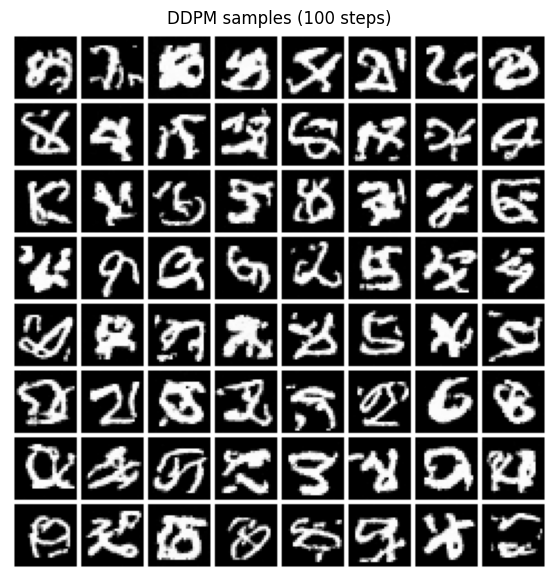

In [10]:
@torch.no_grad()
def ddpm_sample(net, x_T, return_traj=False, sch=spec):
    b, a, ab = sch.betas, sch.alphas, sch.alpha_bars
    x = x_T.clone()
    traj = {T: x.clone()}
    for t in range(T, 0, -1):
        tt = torch.full((x.shape[0],), t, device=device, dtype=torch.long)
        eps = net(x, tt)
        mean = (x - b[t] / (1 - ab[t]).sqrt() * eps) / a[t].sqrt()
        x = mean + b[t].sqrt() * torch.randn_like(x) if t > 1 else mean
        traj[t - 1] = x.clone()
    x = x.clamp(-1, 1)
    return (x, traj) if return_traj else x


N_SHOW = 64
gen = torch.Generator(device="cpu").manual_seed(SEED + 2)
x_T = torch.randn(N_SHOW, 1, 28, 28, generator=gen).to(device)   # shared starting noise for every sampler

torch.manual_seed(SEED + 4)
samples_ddpm, traj_ddpm = ddpm_sample(ema, x_T, return_traj=True)
plt.figure(figsize=(7, 7)); show_grid(samples_ddpm, title="DDPM samples (100 steps)")
plt.savefig(FIG_DIR / "c_ddpm_samples.png", dpi=150, bbox_inches="tight"); plt.show()

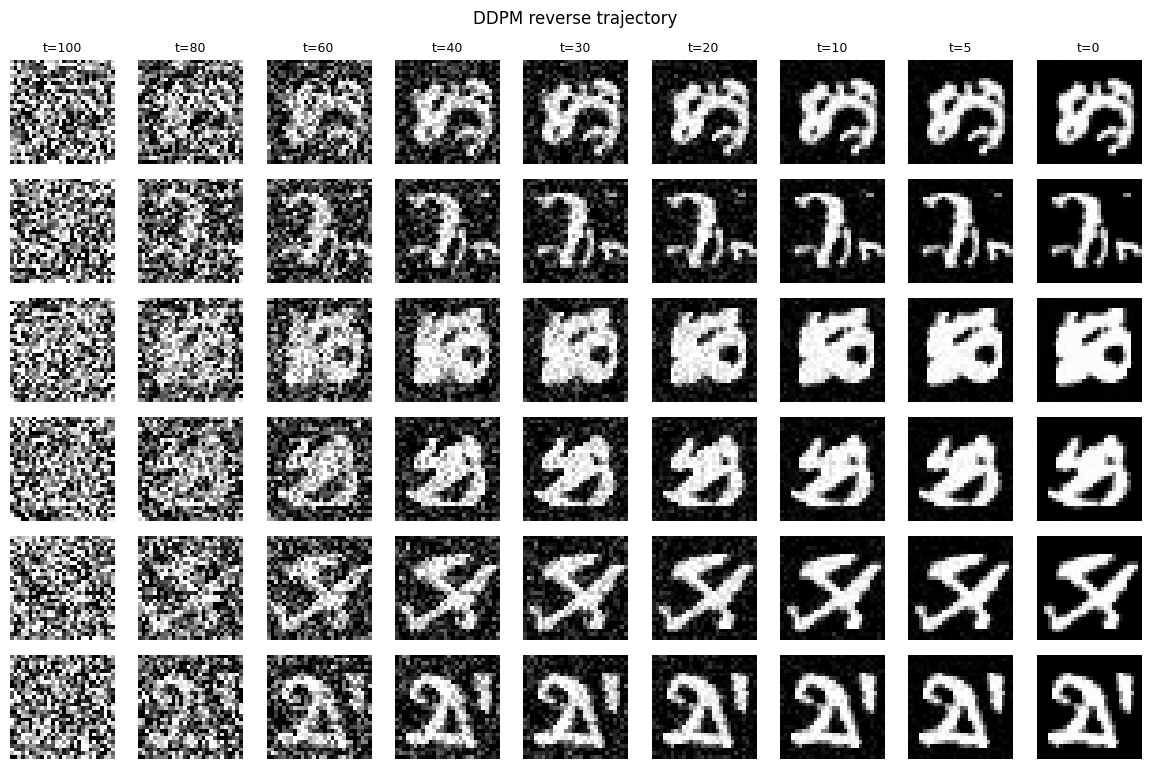

In [11]:
def plot_traj(traj, ts, n=6, title=""):
    fig, axes = plt.subplots(n, len(ts), figsize=(1.3 * len(ts), 1.3 * n))
    for j, t in enumerate(ts):
        for i in range(n):
            axes[i, j].imshow(traj[t][i, 0].clamp(-1, 1).cpu(), cmap="gray", vmin=-1, vmax=1)
            axes[i, j].axis("off")
        axes[0, j].set_title(f"t={t}", fontsize=9)
    fig.suptitle(title); plt.tight_layout()
    return fig

plot_traj(traj_ddpm, [100, 80, 60, 40, 30, 20, 10, 5, 0], title="DDPM reverse trajectory")
plt.savefig(FIG_DIR / "c_ddpm_trajectory.png", dpi=150); plt.show()

## (d) DDIM sampling

DDIM (Song et al., 2021) uses the **same trained network**; only the sampler changes. It first uses the predicted noise to estimate the clean image:

$$\hat x_0 = \frac{x_t - \sqrt{1-\bar\alpha_t}\,\epsilon_\theta(x_t,t)}{\sqrt{\bar\alpha_t}},$$

and then jumps straight to any earlier timestep $s < t$:

$$x_s = \sqrt{\bar\alpha_s}\,\hat x_0 + \sqrt{1-\bar\alpha_s-\sigma^2}\;\epsilon_\theta(x_t,t) + \sigma z,\qquad
\sigma = \eta\sqrt{\tfrac{1-\bar\alpha_s}{1-\bar\alpha_t}}\sqrt{1-\tfrac{\bar\alpha_t}{\bar\alpha_s}}.$$

DDIM's non-Markovian forward process has the same marginals $q(x_t\mid x_0)$ as DDPM's. A model trained with the DDPM objective is therefore also a valid DDIM model, and we can sample with a sub-sequence of $S \le T$ timesteps $\tau_S > \dots > \tau_1 > \tau_0 = 0$. With $\eta = 0$ (used below), the sampler is **deterministic**: the same $x_T$ always gives the same image.

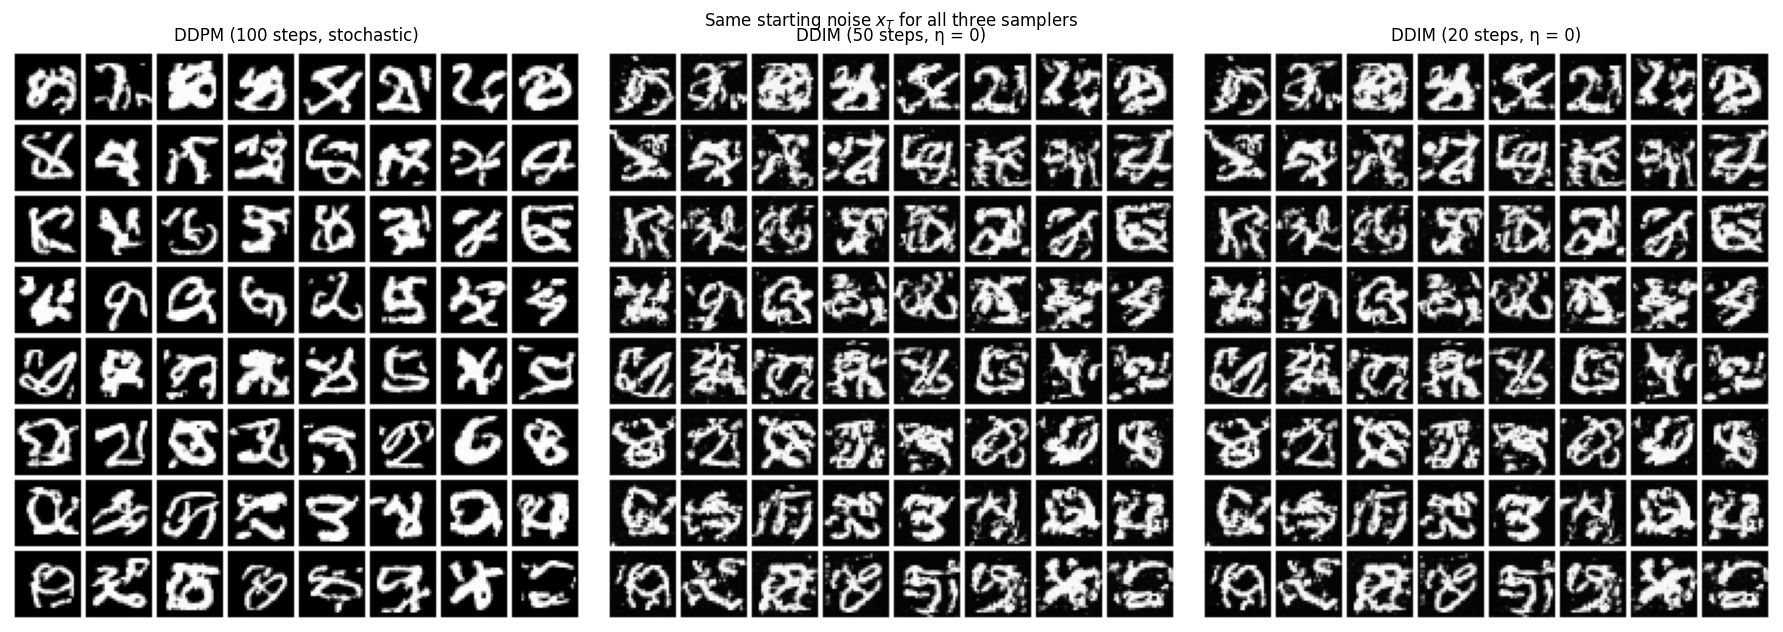

In [12]:
@torch.no_grad()
def ddim_sample(net, x_T, n_steps, eta=0.0, return_traj=False, sch=spec):
    # Evenly spaced sub-sequence T = tau_S > ... > tau_0 = 0
    taus = torch.linspace(T, 0, n_steps + 1).round().long().tolist()
    x = x_T.clone()
    traj = {T: x.clone()}
    for t, s in zip(taus[:-1], taus[1:]):
        tt = torch.full((x.shape[0],), t, device=device, dtype=torch.long)
        eps = net(x, tt)
        ab_t, ab_s = sch.alpha_bars[t], sch.alpha_bars[s]
        x0_hat = ((x - (1 - ab_t).sqrt() * eps) / ab_t.sqrt()).clamp(-1, 1)
        eps = (x - ab_t.sqrt() * x0_hat) / (1 - ab_t).sqrt()          # re-derive eps consistent with clipped x0
        sigma = eta * ((1 - ab_s) / (1 - ab_t) * (1 - ab_t / ab_s)).sqrt()
        x = ab_s.sqrt() * x0_hat + (1 - ab_s - sigma ** 2).sqrt() * eps
        if eta > 0 and s > 0:
            x = x + sigma * torch.randn_like(x)
        traj[s] = x.clone()
    x = x.clamp(-1, 1)
    return (x, traj) if return_traj else x


samples_ddim50, traj_ddim50 = ddim_sample(ema, x_T, 50, return_traj=True)
samples_ddim20, traj_ddim20 = ddim_sample(ema, x_T, 20, return_traj=True)

fig, axes = plt.subplots(1, 3, figsize=(18, 6.4))
show_grid(samples_ddpm,   ax=axes[0], title="DDPM (100 steps, stochastic)")
show_grid(samples_ddim50, ax=axes[1], title="DDIM (50 steps, η = 0)")
show_grid(samples_ddim20, ax=axes[2], title="DDIM (20 steps, η = 0)")
plt.suptitle("Same starting noise $x_T$ for all three samplers", y=0.98)
plt.tight_layout(); plt.savefig(FIG_DIR / "d_ddpm_vs_ddim.png", dpi=150); plt.show()

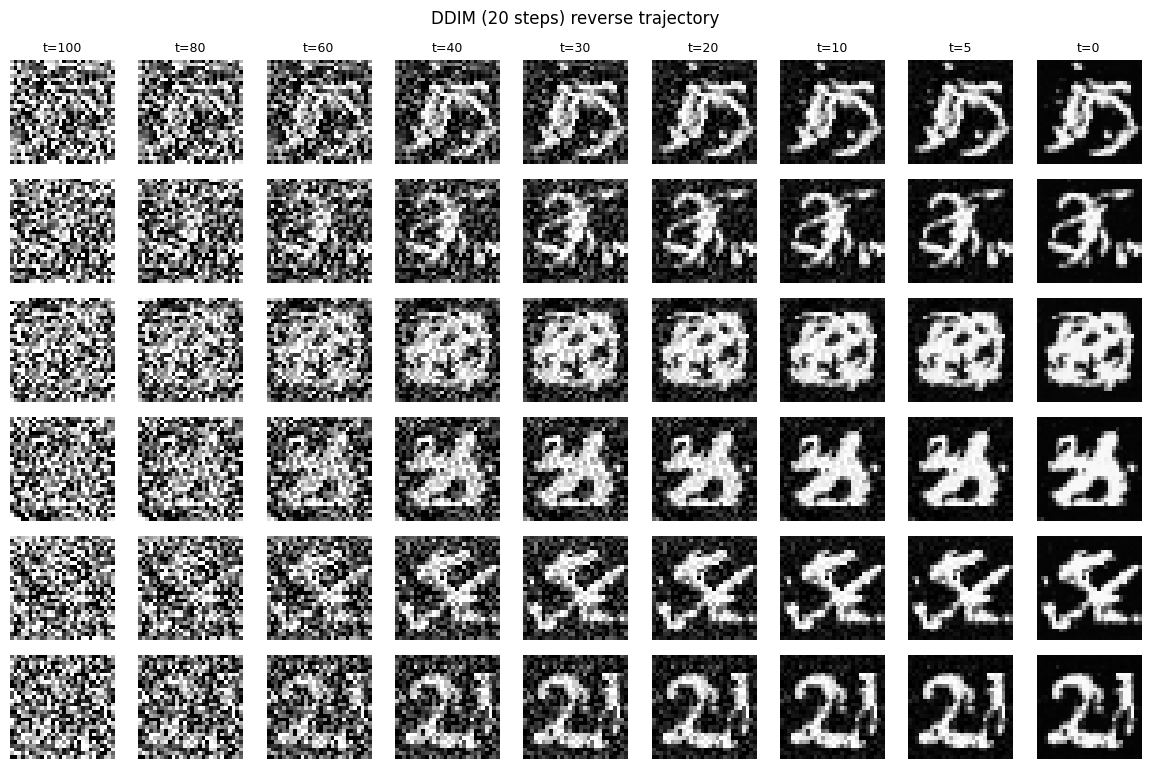

In [13]:
plot_traj(traj_ddim20, [100, 80, 60, 40, 30, 20, 10, 5, 0], title="DDIM (20 steps) reverse trajectory")
plt.savefig(FIG_DIR / "d_ddim20_trajectory.png", dpi=150); plt.show()

### Quantitative comparison

Without a reference Inception network, FID is not meaningful on MNIST. Instead we train a small MNIST classifier (about 99% test accuracy) and use it as a judge. For 1,000 samples per sampler we report:

* **Wall-clock time** and the number of network evaluations (NFE).
* **Mean classifier confidence** (max softmax). Higher means samples look more like clean, unambiguous digits.
* **% confident samples** (max softmax > 0.9).
* **Class-distribution entropy** in bits. The maximum is $\log_2 10 \approx 3.32$, reached when all ten digits appear equally often. Lower values point to mode collapse.
* **Pixel KL**: the KL divergence between the pixel-intensity histogram of the samples and that of real test images. Lower is better.

The same metrics on 1,000 real test images serve as a reference row. We also add two extra configurations to complete the picture: DDIM with 100 steps, and DDIM with 10 steps.

In [14]:
class Classifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.Conv2d(32, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.Conv2d(64, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(), nn.Linear(64 * 7 * 7, 128), nn.ReLU(), nn.Dropout(0.3), nn.Linear(128, 10))

    def forward(self, x):
        return self.net(x)

torch.manual_seed(SEED)
clf = Classifier().to(device)
clf_opt = torch.optim.Adam(clf.parameters(), lr=1e-3)
y_train_d = y_train.to(device)
for ep in range(3):
    clf.train()
    perm = torch.randperm(len(X_train), device=device)
    for i in range(0, len(X_train), 256):
        idx = perm[i:i + 256]
        loss = F.cross_entropy(clf(X_train[idx]), y_train_d[idx])
        clf_opt.zero_grad(); loss.backward(); clf_opt.step()
clf.eval()
with torch.no_grad():
    acc = (clf(X_test.to(device)).argmax(1).cpu() == y_test).float().mean().item()
print(f"judge classifier test accuracy: {acc:.4f}")

judge classifier test accuracy: 0.9907


In [15]:
@torch.no_grad()
def judge(x):
    p = F.softmax(clf(x), dim=1)
    conf = p.max(1).values
    counts = torch.bincount(p.argmax(1), minlength=10).float().cpu()
    q = counts / counts.sum()
    ent = -(q[q > 0] * q[q > 0].log2()).sum().item()
    return conf.mean().item(), (conf > 0.9).float().mean().item(), ent, counts.long().tolist()

real_hist = np.histogram(((X_test[:1000] + 1) / 2).numpy().ravel(), bins=20, range=(0, 1))[0] + 1
real_hist = real_hist / real_hist.sum()
def pixel_kl(x):
    h = np.histogram(((x.clamp(-1, 1) + 1) / 2).cpu().numpy().ravel(), bins=20, range=(0, 1))[0] + 1
    h = h / h.sum()
    return float((h * np.log(h / real_hist)).sum())

N_EVAL = 1000
gen = torch.Generator(device="cpu").manual_seed(SEED + 3)
x_T_eval = torch.randn(N_EVAL, 1, 28, 28, generator=gen).to(device)

def sync():
    if device.type == "cuda": torch.cuda.synchronize()
    elif device.type == "mps": torch.mps.synchronize()

def evaluate(net, sch=spec):
    configs = [("DDPM", 100, lambda x: ddpm_sample(net, x, sch=sch)),
               ("DDIM", 100, lambda x: ddim_sample(net, x, 100, sch=sch)),
               ("DDIM",  50, lambda x: ddim_sample(net, x, 50, sch=sch)),
               ("DDIM",  20, lambda x: ddim_sample(net, x, 20, sch=sch)),
               ("DDIM",  10, lambda x: ddim_sample(net, x, 10, sch=sch))]
    rows = []
    torch.manual_seed(SEED + 4)
    for name, nfe, fn in configs:
        sync(); t0 = time.time()
        x = fn(x_T_eval)
        sync(); dt = time.time() - t0
        conf, frac, ent, counts = judge(x)
        rows.append((f"{name} ({nfe} steps)", nfe, dt, conf, frac, ent, pixel_kl(x), counts))
    conf, frac, ent, counts = judge(X_test[:N_EVAL].to(device))
    rows.append(("Real MNIST (test)", 0, 0.0, conf, frac, ent, 0.0, counts))
    return rows

def print_table(rows):
    print(f"{'sampler':<20}{'NFE':>5}{'time (s)':>10}{'mean conf':>11}{'% conf>0.9':>12}{'class H (bits)':>16}{'pixel KL':>10}")
    for r in rows:
        print(f"{r[0]:<20}{r[1]:>5}{r[2]:>10.2f}{r[3]:>11.3f}{100 * r[4]:>11.1f}%{r[5]:>16.3f}{r[6]:>10.4f}")
    print("\nclass counts (0-9):")
    for r in rows:
        print(f"{r[0]:<20}{r[7]}")

rows = evaluate(ema)
print_table(rows)

sampler               NFE  time (s)  mean conf  % conf>0.9  class H (bits)  pixel KL
DDPM (100 steps)      100     67.07      0.806       47.4%           2.891    0.0689
DDIM (100 steps)      100     67.09      0.776       41.0%           2.661    0.1859
DDIM (50 steps)        50     32.48      0.776       40.8%           2.657    0.1858
DDIM (20 steps)        20     12.81      0.775       40.6%           2.654    0.1945
DDIM (10 steps)        10      6.38      0.774       39.9%           2.653    0.2203
Real MNIST (test)       0      0.00      0.988       96.7%           3.309    0.0000

class counts (0-9):
DDPM (100 steps)    [57, 7, 230, 95, 79, 77, 58, 84, 278, 35]
DDIM (100 steps)    [28, 7, 278, 88, 88, 51, 41, 65, 326, 28]
DDIM (50 steps)     [28, 7, 279, 88, 88, 51, 38, 67, 326, 28]
DDIM (20 steps)     [29, 7, 279, 90, 87, 50, 37, 66, 327, 28]
DDIM (10 steps)     [28, 7, 283, 88, 85, 50, 38, 67, 325, 29]
Real MNIST (test)   [85, 127, 114, 108, 109, 87, 87, 102, 86, 95]


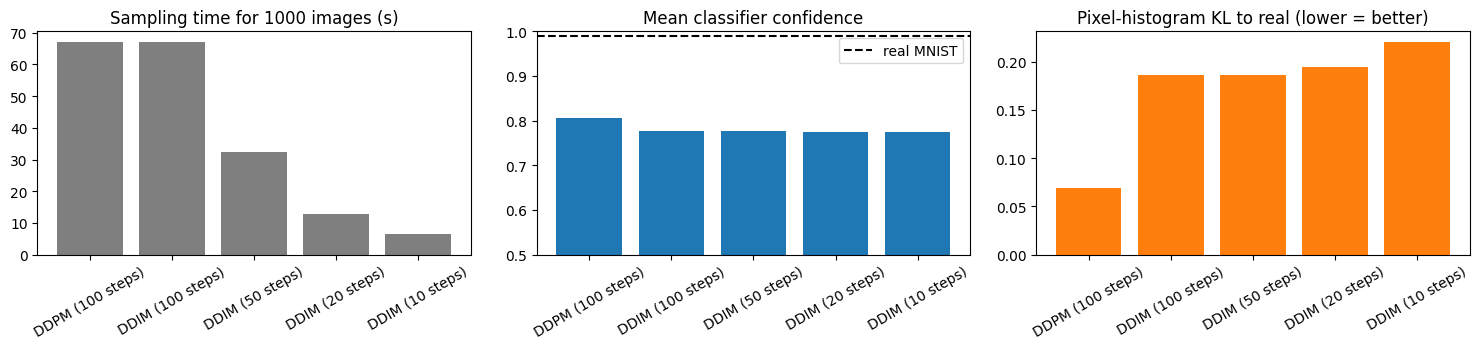

In [16]:
labels = [r[0] for r in rows[:-1]]
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].bar(labels, [r[2] for r in rows[:-1]], color="tab:gray"); ax[0].set_title("Sampling time for 1000 images (s)")
ax[1].bar(labels, [r[3] for r in rows[:-1]], color="tab:blue"); ax[1].axhline(rows[-1][3], ls="--", c="k", label="real MNIST")
ax[1].set_ylim(0.5, 1.0); ax[1].set_title("Mean classifier confidence"); ax[1].legend()
ax[2].bar(labels, [r[6] for r in rows[:-1]], color="tab:orange"); ax[2].set_title("Pixel-histogram KL to real (lower = better)")
for a in ax: a.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig(FIG_DIR / "d_metrics.png", dpi=150); plt.show()

### Sampling speed

The time column above comes from a single pass per sampler, so a momentary slowdown of the machine (thermal or power throttling) can distort it. Here every sampler is timed on a batch of 256 images, interleaved over 5 rounds after a warm-up pass, and we report the fastest (minimum) time per sampler. Outside interference can only add time, so the minimum is the most faithful estimate (the same convention `timeit` uses). Every sampler calls the same network once per step, so the cost should scale with the number of function evaluations (NFE).

In [17]:
x_bench = torch.randn(256, 1, 28, 28, generator=torch.Generator(device="cpu").manual_seed(SEED + 5)).to(device)
ddim_sample(ema, x_bench, 10)                                # warm-up

samplers = [("DDPM (100 steps)", 100, lambda x: ddpm_sample(ema, x)),
            ("DDIM (100 steps)", 100, lambda x: ddim_sample(ema, x, 100)),
            ("DDIM (50 steps)",   50, lambda x: ddim_sample(ema, x, 50)),
            ("DDIM (20 steps)",   20, lambda x: ddim_sample(ema, x, 20)),
            ("DDIM (10 steps)",   10, lambda x: ddim_sample(ema, x, 10))]
times = {name: [] for name, _, _ in samplers}
for _ in range(5):                                           # interleaved rounds
    for name, _, fn in samplers:
        sync(); t0 = time.time(); fn(x_bench); sync(); times[name].append(time.time() - t0)

timings = [(name, nfe, min(times[name])) for name, nfe, _ in samplers]
ddpm_time = timings[0][2]
print(f"{'sampler':<20}{'NFE':>5}{'time / 256 imgs (s)':>22}{'ms / image':>12}{'speed-up vs DDPM':>18}")
for name, nfe, dt in timings:
    print(f"{name:<20}{nfe:>5}{dt:>22.2f}{1000 * dt / 256:>12.2f}{ddpm_time / dt:>17.1f}x")

sampler               NFE   time / 256 imgs (s)  ms / image  speed-up vs DDPM
DDPM (100 steps)      100                 16.77       65.50              1.0x
DDIM (100 steps)      100                 16.59       64.79              1.0x
DDIM (50 steps)        50                  8.23       32.16              2.0x
DDIM (20 steps)        20                  3.30       12.87              5.1x
DDIM (10 steps)        10                  1.65        6.46             10.1x


### DDIM determinism and consistency across step counts

With $\eta = 0$, DDIM maps each starting noise $x_T$ to a fixed image. The next cell checks two things. First, running DDIM twice from the same $x_T$ gives identical outputs. Second, because every DDIM run follows (a discretization of) the same probability-flow ODE, DDIM-100, -50, -20 and -10 started from the same $x_T$ should produce **the same digit**, with fewer steps giving a slightly coarser result. DDPM injects fresh noise at every step, so running it twice from the same $x_T$ gives a different digit each time.

DDIM-20 run twice from same x_T -> max abs difference: 0.0


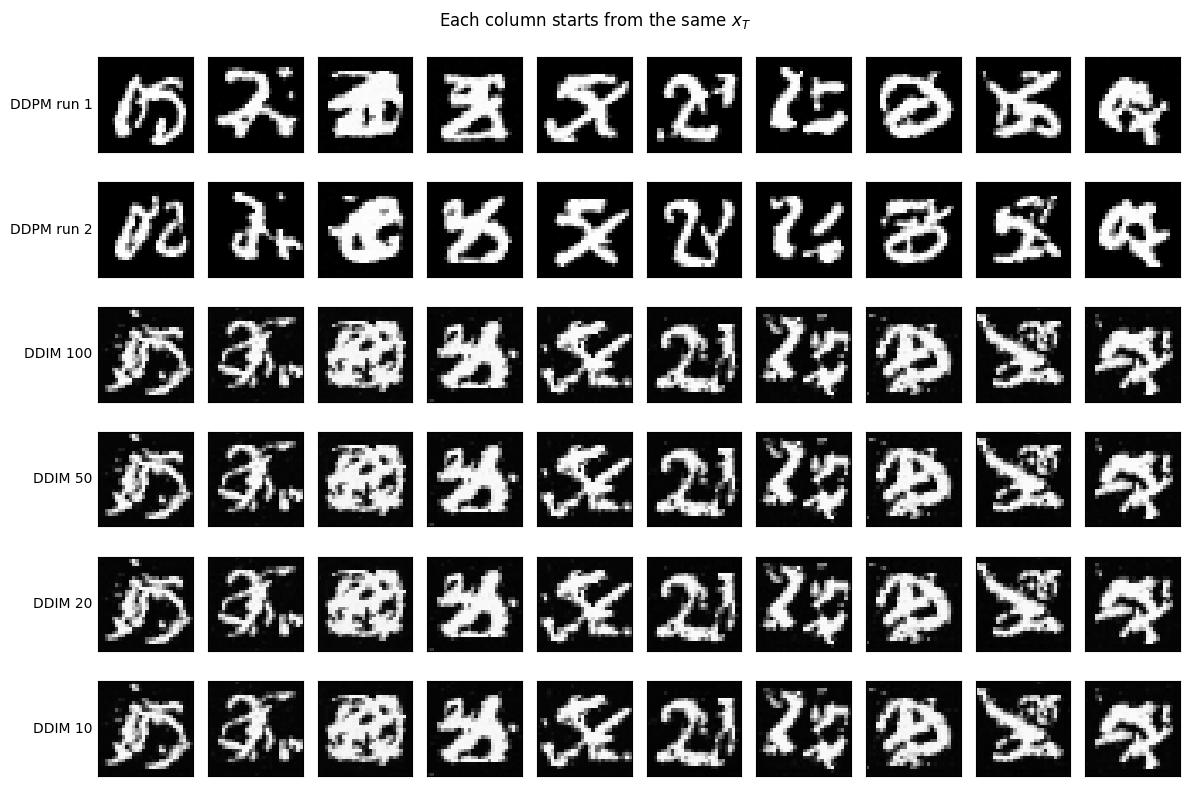

DDPM run 2  predicted digit agrees with DDPM run 1: 30% of columns
DDIM 50     predicted digit agrees with DDIM 100  : 100% of columns
DDIM 20     predicted digit agrees with DDIM 100  : 100% of columns
DDIM 10     predicted digit agrees with DDIM 100  : 100% of columns


In [18]:
x_T_small = x_T[:10]
rows_img = {"DDPM run 1": ddpm_sample(ema, x_T_small), "DDPM run 2": ddpm_sample(ema, x_T_small)}
for n in [100, 50, 20, 10]:
    rows_img[f"DDIM {n}"] = ddim_sample(ema, x_T_small, n)
rep = ddim_sample(ema, x_T_small, 20)
print("DDIM-20 run twice from same x_T -> max abs difference:", (rep - rows_img["DDIM 20"]).abs().max().item())

fig, axes = plt.subplots(len(rows_img), 10, figsize=(12, 1.35 * len(rows_img)))
for i, (name, x) in enumerate(rows_img.items()):
    for j in range(10):
        axes[i, j].imshow(x[j, 0].cpu(), cmap="gray", vmin=-1, vmax=1); axes[i, j].set_xticks([]); axes[i, j].set_yticks([])
    axes[i, 0].set_ylabel(name, rotation=0, ha="right", va="center", fontsize=10)
fig.suptitle("Each column starts from the same $x_T$")
plt.tight_layout(); plt.savefig(FIG_DIR / "d_consistency.png", dpi=150); plt.show()

with torch.no_grad():
    preds = {k: clf(v).argmax(1).cpu() for k, v in rows_img.items()}
for k in ["DDPM run 2", "DDIM 50", "DDIM 20", "DDIM 10"]:
    ref = "DDPM run 1" if k.startswith("DDPM") else "DDIM 100"
    print(f"{k:<11} predicted digit agrees with {ref:<10}: {(preds[k] == preds[ref]).float().mean().item() * 100:.0f}% of columns")

### Effect of the short schedule ($\bar\alpha_T \approx 0.37$)

At training time the network only ever saw $x_{100} = 0.6\,x_0 + 0.8\,\epsilon$, but both samplers start from $x_{100}\sim\mathcal N(0,I)$. The cell below measures how far apart these two distributions are, using the per-image pixel standard deviation. It then shows what $\hat x_0$ the model predicts at the very first reverse step.

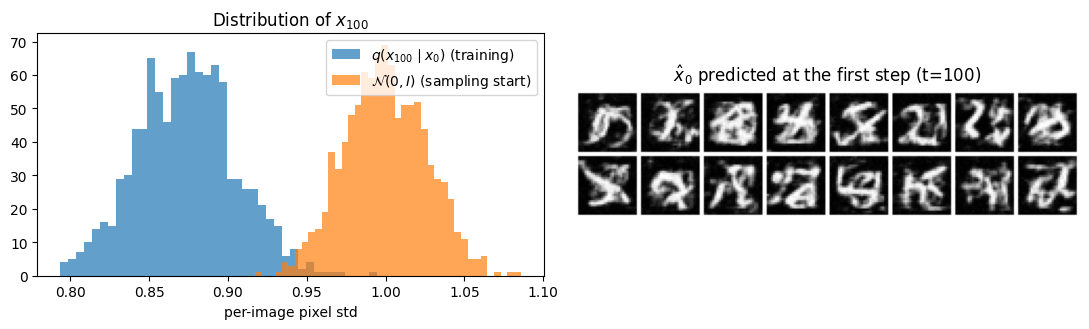

In [19]:
with torch.no_grad():
    xT_train, _ = q_sample(X_test[:1000].to(device), torch.full((1000,), T, device=device, dtype=torch.long))
    std_train = xT_train.flatten(1).std(1).cpu().numpy()
    std_pure = torch.randn(1000, 1, 28, 28).flatten(1).std(1).numpy()
    tt = torch.full((16,), T, device=device, dtype=torch.long)
    x0_first = ((x_T[:16] - (1 - alpha_bars[T]).sqrt() * ema(x_T[:16], tt)) / alpha_bars[T].sqrt())

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].hist(std_train, bins=40, alpha=0.7, label=r"$q(x_{100}\mid x_0)$ (training)")
ax[0].hist(std_pure, bins=40, alpha=0.7, label=r"$\mathcal{N}(0,I)$ (sampling start)")
ax[0].set_xlabel("per-image pixel std"); ax[0].legend(); ax[0].set_title("Distribution of $x_{100}$")
show_grid(x0_first, nrow=8, ax=ax[1], title=r"$\hat x_0$ predicted at the first step (t=100)")
plt.tight_layout(); plt.savefig(FIG_DIR / "d_xT_mismatch.png", dpi=150); plt.show()

## Extra: same experiment with a schedule that reaches pure noise

To check that the issue above comes from the schedule and not from the model or the samplers, we repeat parts (b)–(d) with **everything identical except β**. The linear schedule is scaled by $1000/T = 10$, so $\beta_t$ runs from $10^{-3}$ to $0.2$. This is the usual rule for keeping the DDPM schedule's endpoint when $T$ shrinks (Nichol & Dhariwal, 2021). The architecture, $T=100$, batch size, epochs, optimizer and samplers are all unchanged.

This section goes beyond what the assignment asks for. Parts (a)–(d) above use the given configuration exactly.

scaled schedule: alpha_bar_T = 2.04e-05  (vs 0.364 for the assignment schedule)


epoch   1/50  loss 0.0624  (104s)


epoch   6/50  loss 0.0250  (602s)


epoch  11/50  loss 0.0235  (1099s)


epoch  16/50  loss 0.0229  (1599s)


...

epoch  31/50  loss 0.0217  (3100s)


epoch  36/50  loss 0.0214  (3596s)


epoch  41/50  loss 0.0210  (4093s)


epoch  46/50  loss 0.0209  (4591s)


epoch  50/50  loss 0.0210  (4989s)


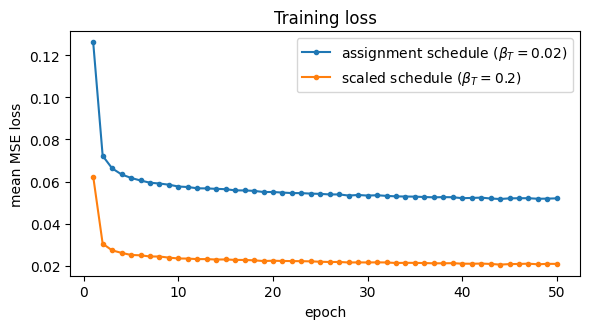

In [20]:
scaled = Schedule(BETA_START * 1000 / T, BETA_END * 1000 / T)
print(f"scaled schedule: alpha_bar_T = {scaled.alpha_bars[T].item():.2e}  (vs {alpha_bars[T].item():.3f} for the assignment schedule)")

torch.manual_seed(SEED)
model_s = MiniUNet().to(device)
ema_s, iter_losses_s, epoch_losses_s = train(model_s, sch=scaled, ckpt="ddpm_mnist_scaled.pt")

plt.figure(figsize=(6, 3.4))
plt.plot(np.arange(1, EPOCHS + 1), epoch_losses, marker="o", ms=3, label=r"assignment schedule ($\beta_T=0.02$)")
plt.plot(np.arange(1, EPOCHS + 1), epoch_losses_s, marker="o", ms=3, label=r"scaled schedule ($\beta_T=0.2$)")
plt.xlabel("epoch"); plt.ylabel("mean MSE loss"); plt.legend(); plt.title("Training loss")
plt.tight_layout(); plt.savefig(FIG_DIR / "x_training_loss_both.png", dpi=150); plt.show()

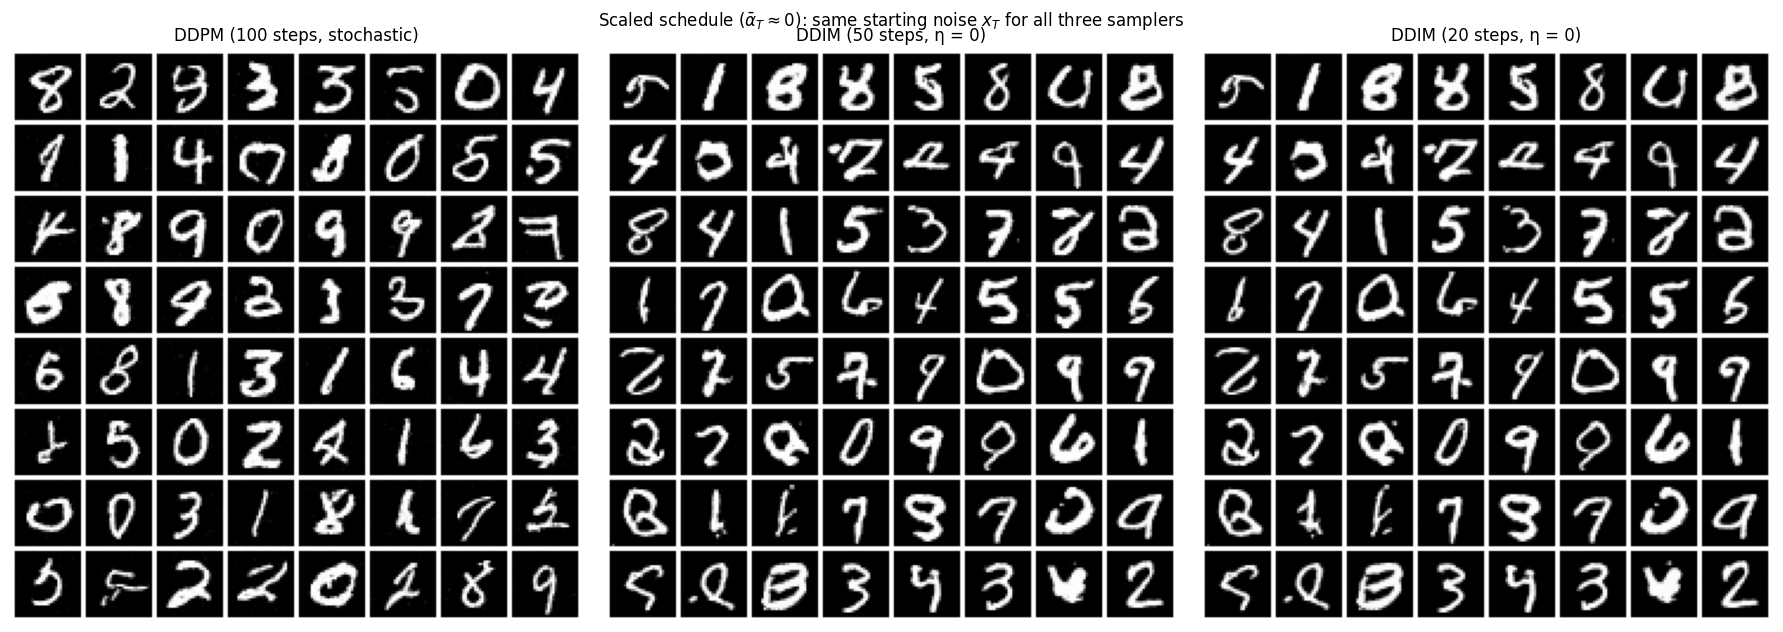

sampler               NFE  time (s)  mean conf  % conf>0.9  class H (bits)  pixel KL
DDPM (100 steps)      100     67.76      0.942       83.2%           3.313    0.0013
DDIM (100 steps)      100     69.15      0.932       80.3%           3.317    0.0009
DDIM (50 steps)        50     32.79      0.931       80.2%           3.318    0.0009
DDIM (20 steps)        20     13.34      0.926       78.7%           3.316    0.0020
DDIM (10 steps)        10      6.43      0.915       76.2%           3.312    0.0070
Real MNIST (test)       0      0.00      0.988       96.7%           3.309    0.0000

class counts (0-9):
DDPM (100 steps)    [84, 97, 82, 118, 102, 97, 97, 117, 102, 104]
DDIM (100 steps)    [98, 96, 104, 105, 95, 97, 98, 103, 86, 118]
DDIM (50 steps)     [99, 94, 105, 104, 93, 101, 96, 104, 87, 117]
DDIM (20 steps)     [94, 86, 110, 106, 96, 103, 96, 101, 91, 117]
DDIM (10 steps)     [87, 81, 115, 115, 97, 105, 92, 99, 92, 117]
Real MNIST (test)   [85, 127, 114, 108, 109, 87, 87, 102

In [21]:
s_ddpm = ddpm_sample(ema_s, x_T, sch=scaled)
s_ddim50 = ddim_sample(ema_s, x_T, 50, sch=scaled)
s_ddim20 = ddim_sample(ema_s, x_T, 20, sch=scaled)

fig, axes = plt.subplots(1, 3, figsize=(18, 6.4))
show_grid(s_ddpm,   ax=axes[0], title="DDPM (100 steps, stochastic)")
show_grid(s_ddim50, ax=axes[1], title="DDIM (50 steps, η = 0)")
show_grid(s_ddim20, ax=axes[2], title="DDIM (20 steps, η = 0)")
plt.suptitle(r"Scaled schedule ($\bar\alpha_T \approx 0$): same starting noise $x_T$ for all three samplers", y=0.98)
plt.tight_layout(); plt.savefig(FIG_DIR / "x_ddpm_vs_ddim_scaled.png", dpi=150); plt.show()

rows_s = evaluate(ema_s, sch=scaled)
print_table(rows_s)

## Discussion: DDPM vs. DDIM

### Summary of results

Judge-classifier metrics on 1,000 samples per sampler, plus the speed-up from the "Sampling speed" cell:

| Sampler | NFE | Speed-up vs DDPM | Assignment schedule: mean conf / % conf>0.9 / class H / pixel KL | Scaled schedule: mean conf / % conf>0.9 / class H / pixel KL |
|---|---|---|---|---|
| DDPM | 100 | 1× | **0.806 / 47.4% / 2.89 / 0.069** | **0.942 / 83.2%** / 3.313 / 0.0013 |
| DDIM | 100 | 1.0× | 0.776 / 41.0% / 2.66 / 0.186 | 0.932 / 80.3% / 3.317 / **0.0009** |
| DDIM | 50 | 2.0× | 0.776 / 40.8% / 2.66 / 0.186 | 0.931 / 80.2% / 3.318 / **0.0009** |
| DDIM | 20 | 5.1× | 0.775 / 40.6% / 2.65 / 0.195 | 0.926 / 78.7% / 3.316 / 0.0020 |
| DDIM | 10 | 10.1× | 0.774 / 39.9% / 2.65 / 0.220 | 0.915 / 76.2% / 3.312 / 0.0070 |
| Real MNIST | – | – | 0.988 / 96.7% / 3.309 / 0 | same |

### 1. Speed: DDIM's main advantage

DDPM's reverse update is derived for a single step $t \to t-1$ of the Markov chain, so DDPM has to make all $T = 100$ network calls. DDIM rewrites each update as "predict $\hat x_0$, then re-noise to the level of the target timestep." That update works for any target timestep $s < t$, so DDIM can skip timesteps. The cost is therefore proportional to the number of steps. DDIM-100 costs the same as DDPM (16.6 s vs 16.8 s for 256 images). DDIM-50 is 2.0× faster, DDIM-20 is 5.1× faster, and DDIM-10 is 10.1× faster. No retraining is needed. Both samplers use the same $\epsilon_\theta$, because DDIM's non-Markovian forward process has the same marginals $q(x_t \mid x_0)$ that the network was trained on.

### 2. Quality vs. number of steps

With the scaled schedule, where the comparison is fair, cutting DDIM from 100 to 50 steps is essentially free: confidence goes from 0.932 to 0.931 and pixel KL is unchanged. At 20 steps quality drops only slightly (0.926, 78.7% confident). At 10 steps the drop is clearly visible: confidence 0.915, only 76.2% confident, and the pixel KL is about 8× higher than at 50 steps, with some thinner or broken strokes. Each DDIM step approximates the denoising trajectory as locally linear in $\hat x_0$. With fewer, larger steps that discretization error grows, but it grows slowly, because $\hat x_0$ is already a good estimate after the first few high-noise steps. The 20-step and 50-step DDIM grids are hard to tell apart by eye.

DDPM-100 has slightly higher classifier confidence than any DDIM setting (0.942 vs 0.932 at equal NFE). DDIM-100 and DDIM-50 have a lower pixel KL. In short, DDPM's injected noise gives slightly crisper, more "typical" digits, while DDIM matches the overall intensity statistics a bit better. All samplers cover all ten classes evenly (entropy 3.31 to 3.32 bits, the same as real MNIST at 3.309), so none of them shows mode collapse.

### 3. Stochastic vs. deterministic

* **DDPM is stochastic.** It adds fresh Gaussian noise $\sigma_t z$ at every step. Two DDPM runs from the *same* $x_T$ produce different images: in the consistency figure, the predicted digit matched in only 30% of the columns. The final image depends on all 100 noise draws, not only on $x_T$.
* **DDIM ($\eta = 0$) is deterministic.** Running it twice from the same $x_T$ gives a bit-for-bit identical result (max abs difference 0.0). Because every DDIM run discretizes the same underlying ODE, DDIM-100, -50, -20 and -10 started from the same noise produce **the same digit** (100% class agreement), and the grids for different step counts look almost identical. As a result, $x_T$ works as a latent code for the image. That makes DDIM useful for reproducibility, for interpolating between noise vectors, and for inverting real images back to noise. DDPM has none of these properties.

### 4. Effect of the assignment's schedule ($T = 100$, $\beta_T = 0.02$)

With the given configuration, $\bar\alpha_{100} = 0.364$. So the training inputs at $t = 100$ are $0.60\,x_0 + 0.80\,\epsilon$, which is not pure noise: their per-image std is about 0.87. Both samplers start from $x_{100} \sim \mathcal N(0, I)$, whose std is 1.0 (see the $x_{100}$ distribution plot). The network has never seen inputs like this. It reads the extra variance in the noise as stroke content, and its first $\hat x_0$ prediction is already a tangle of strokes. This is why the samples from this model look like scribbles more than digits. The class distribution is also skewed. "8" and "2", the classes that best fit many overlapping or curly strokes, take about half of all samples (DDPM 278 + 230, DDIM-50 326 + 279, out of 1,000). Almost none are classified as "1" (7 out of 1,000).

The two samplers handle this mismatch differently:

* **DDPM recovers better** (confidence 0.806, entropy 2.89, KL 0.069). Its noise injection mixes the state at every step and partially corrects the wrong starting distribution, acting much like a Langevin correction step. Its samples have cleaner, connected strokes.
* **DDIM is hurt more** (confidence about 0.776, entropy about 2.66, KL 0.19 to 0.22, for every step count). A deterministic ODE has no mechanism to remove an error in its initial condition. The out-of-distribution component of $x_T$ is carried all the way to $x_0$, which shows up as noisy, fragmented strokes. Step count barely matters here, because the error is set at $t = T$ rather than accumulated through discretization.

Re-training with $\beta_t$ scaled ×10 (0.001 → 0.2, so $\bar\alpha_T \approx 2\times10^{-5}$) and changing nothing else removes the mismatch. Every metric jumps: confidence goes from about 0.78–0.81 to about 0.93–0.94, and pixel KL drops about 50× for DDPM and about 200× for DDIM-50. The samples become clearly readable digits, and DDPM and DDIM then behave as the papers describe. This confirms that the poor samples come from the schedule, not from the network or the sampler code. A diffusion model's terminal distribution has to match the prior that sampling starts from.

### 5. Takeaways

1. DDPM and DDIM use the same trained network; only the reverse update differs.
2. DDIM gives a 2× to 5× speed-up (50 to 20 steps) at almost no visible cost to quality, and it degrades gracefully down to about 10 steps.
3. DDPM is stochastic and somewhat more robust to errors, for example a wrong $x_T$ distribution. DDIM is deterministic, gives reproducible samples, and gives a meaningful noise-to-image mapping.
4. The noise schedule has to drive $\bar\alpha_T$ close to 0. Otherwise both samplers start from the wrong distribution, and the deterministic DDIM sampler suffers most.